In [1]:
'''Design and implement a comprehensive model versioning system, integrating tools like MLflow or DVC to track, manage,
 and roll back model versions while maintaining reproducibility and auditability.'''

'Design and implement a comprehensive model versioning system, integrating tools like MLflow or DVC to track, manage,\n and roll back model versions while maintaining reproducibility and auditability.'

In [2]:
# import required libraries
import os
import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient

In [3]:
# load dataset and inspect pharmacy sales records
file_name = 'global_pharmacy_sales_data.csv' if os.path.exists('global_pharmacy_sales_data.csv') else 'global_pharmacy_salles_data.csv'
df = pd.read_csv(file_name)
print('dataset shape:', df.shape)
df.head()

dataset shape: (177990, 14)


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


In [4]:
# explore target distribution and feature statistics
print('target units_sold summary:')
print(df['units_sold'].describe())
print('\nfeature info:')
print(df[['unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']].describe())

target units_sold summary:
count    177990.000000
mean        447.913849
std         338.924528
min          31.000000
25%         284.000000
50%         387.000000
75%         529.000000
max        8704.000000
Name: units_sold, dtype: float64

feature info:
          unit_price    stock_level  expiry_days_remaining     covid_flag
count  177990.000000  177990.000000          177990.000000  177990.000000
mean       52.554729    4552.991780             374.038109       0.333519
std        27.421909     346.608511             199.759193       0.471471
min         5.000000       0.000000              30.000000       0.000000
25%        28.770000    4443.000000             200.000000       0.000000
50%        52.600000    4598.000000             374.000000       0.000000
75%        76.310000    4735.000000             547.000000       1.000000
max       100.000000    5124.000000             720.000000       1.000000


In [5]:
# preprocess features and split training and testing sets
features = ['unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']
X = df[features].values.astype(np.float32)
y = df['units_sold'].values.astype(np.float32)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('training samples:', X_train.shape[0], 'testing samples:', X_test.shape[0])

training samples: 142392 testing samples: 35598


In [6]:
# configure mlflow sqlite backend and initialize experiment
mlflow.set_tracking_uri('sqlite:///mlflow_pharmacy_registry.db')
client = MlflowClient('sqlite:///mlflow_pharmacy_registry.db')
experiment_name = 'pharmacy_sales_versioning_suite'
mlflow.set_experiment(experiment_name)
experiment = mlflow.get_experiment_by_name(experiment_name)
print('experiment id:', experiment.experiment_id, 'tracking uri:', mlflow.get_tracking_uri())

2026/11/05 22:57:11 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/05 22:57:11 INFO mlflow.store.db.utils: Updating database tables
2026/11/05 22:57:14 INFO mlflow.tracking.fluent: Experiment with name 'pharmacy_sales_versioning_suite' does not exist. Creating a new experiment.


experiment id: 1 tracking uri: sqlite:///mlflow_pharmacy_registry.db


In [7]:
# train and version baseline linear regression model v1
model_name = 'pharmacy_sales_forecaster'
with mlflow.start_run(run_name='run_v1_linear_baseline') as run_v1:
    lr = LinearRegression()
    lr.fit(X_train[:25000], y_train[:25000])
    preds_v1 = lr.predict(X_test)
    
    rmse_v1 = root_mean_squared_error(y_test, preds_v1)
    mae_v1 = mean_absolute_error(y_test, preds_v1)
    r2_v1 = r2_score(y_test, preds_v1)
    
    mlflow.log_param('version_tag', 'v1')
    mlflow.log_param('algorithm', 'LinearRegression')
    mlflow.log_metric('rmse', rmse_v1)
    mlflow.log_metric('mae', mae_v1)
    mlflow.log_metric('r2', r2_v1)
    
    mlflow.sklearn.log_model(
        sk_model=lr,
        name='model',
        serialization_format='pickle',
        registered_model_name=model_name
    )
    print(f'v1 linear model registered: rmse={rmse_v1:.2f}, r2={r2_v1:.4f}')

2026/11/05 22:57:14 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/11/05 22:57:14 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably

v1 linear model registered: rmse=117.18, r2=0.8819


Successfully registered model 'pharmacy_sales_forecaster'.
Created version '1' of model 'pharmacy_sales_forecaster'.


In [8]:
# train and version random forest model v2
with mlflow.start_run(run_name='run_v2_random_forest') as run_v2:
    rf = RandomForestRegressor(n_estimators=25, max_depth=8, random_state=42, n_jobs=-1)
    rf.fit(X_train[:25000], y_train[:25000])
    preds_v2 = rf.predict(X_test)
    
    rmse_v2 = root_mean_squared_error(y_test, preds_v2)
    mae_v2 = mean_absolute_error(y_test, preds_v2)
    r2_v2 = r2_score(y_test, preds_v2)
    
    mlflow.log_param('version_tag', 'v2')
    mlflow.log_param('algorithm', 'RandomForestRegressor')
    mlflow.log_param('n_estimators', 25)
    mlflow.log_param('max_depth', 8)
    mlflow.log_metric('rmse', rmse_v2)
    mlflow.log_metric('mae', mae_v2)
    mlflow.log_metric('r2', r2_v2)
    
    mlflow.sklearn.log_model(
        sk_model=rf,
        name='model',
        serialization_format='pickle',
        registered_model_name=model_name
    )
    print(f'v2 random forest model registered: rmse={rmse_v2:.2f}, r2={r2_v2:.4f}')

2026/11/05 22:57:37 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


v2 random forest model registered: rmse=94.16, r2=0.9237


Registered model 'pharmacy_sales_forecaster' already exists. Creating a new version of this model...
Created version '2' of model 'pharmacy_sales_forecaster'.


In [9]:
# train and version gradient boosting model v3
with mlflow.start_run(run_name='run_v3_gradient_boosting') as run_v3:
    gb = GradientBoostingRegressor(n_estimators=35, max_depth=6, learning_rate=0.1, random_state=42)
    gb.fit(X_train[:25000], y_train[:25000])
    preds_v3 = gb.predict(X_test)
    
    rmse_v3 = root_mean_squared_error(y_test, preds_v3)
    mae_v3 = mean_absolute_error(y_test, preds_v3)
    r2_v3 = r2_score(y_test, preds_v3)
    
    mlflow.log_param('version_tag', 'v3')
    mlflow.log_param('algorithm', 'GradientBoostingRegressor')
    mlflow.log_param('n_estimators', 35)
    mlflow.log_param('max_depth', 6)
    mlflow.log_param('learning_rate', 0.1)
    mlflow.log_metric('rmse', rmse_v3)
    mlflow.log_metric('mae', mae_v3)
    mlflow.log_metric('r2', r2_v3)
    
    mlflow.sklearn.log_model(
        sk_model=gb,
        name='model',
        serialization_format='pickle',
        registered_model_name=model_name
    )
    print(f'v3 gradient boosting model registered: rmse={rmse_v3:.2f}, r2={r2_v3:.4f}')

2026/11/05 22:57:46 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


v3 gradient boosting model registered: rmse=93.46, r2=0.9249


Registered model 'pharmacy_sales_forecaster' already exists. Creating a new version of this model...
Created version '3' of model 'pharmacy_sales_forecaster'.


In [10]:
# query and compare all logged model versions
runs_data = mlflow.search_runs(experiment_ids=[experiment.experiment_id])
comparison_df = runs_data[['params.version_tag', 'params.algorithm', 'metrics.rmse', 'metrics.mae', 'metrics.r2']].dropna()
comparison_df.columns = ['version', 'algorithm', 'rmse', 'mae', 'r2_score']
comparison_df = comparison_df.sort_values('version').reset_index(drop=True)
print(comparison_df)

  version                  algorithm        rmse        mae  r2_score
0      v1           LinearRegression  117.178680  95.767555  0.881895
1      v2      RandomForestRegressor   94.162224  74.075756  0.923735
2      v3  GradientBoostingRegressor   93.464036  73.846824  0.924862


In [11]:
# manage model registry and promote champion version to production
all_registered = client.search_model_versions(f"name='{model_name}'")
for item in all_registered:
    print(f'registered version: {item.version}, stage: {item.current_stage}, run_id: {item.run_id}')

best_version = str(all_registered[0].version)
client.transition_model_version_stage(
    name=model_name,
    version=best_version,
    stage='Production',
    archive_existing_versions=True
)
promoted_model = client.get_model_version(name=model_name, version=best_version)
print(f'promoted version {promoted_model.version} to stage: {promoted_model.current_stage}')

registered version: 3, stage: None, run_id: b48f676aecec495bbe74b38b5dfb2a50
registered version: 2, stage: None, run_id: 1e6c589cac884265984ef78c72613c1e
registered version: 1, stage: None, run_id: fb983047394a4951b835bdee7c1dad1d
promoted version 3 to stage: Production


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_8340\3125071512.py:7: FutureWarning: ``mlflow.tracking.client.MlflowClient.transition_model_version_stage`` is deprecated since 2.9.0. Model registry stages will be removed in a future major release. To learn more about the deprecation of model registry stages, see our migration guide here: https://mlflow.org/docs/latest/model-registry.html#migrating-from-stages
  client.transition_model_version_stage(


In [12]:
# audit model lineage and execute version rollback
print('executing automated rollback to version 1...')
client.transition_model_version_stage(
    name=model_name,
    version='1',
    stage='Production',
    archive_existing_versions=True
)

active_version = client.get_model_version(name=model_name, version='1')
print(f'rollback verified: version {active_version.version} is now in stage {active_version.current_stage}')

rolled_back_model = mlflow.sklearn.load_model(f'models:/{model_name}/1')
sample_preds = rolled_back_model.predict(X_test[:5])
print('sample inference from rolled back model version 1:', sample_preds)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_8340\3726029195.py:3: FutureWarning: ``mlflow.tracking.client.MlflowClient.transition_model_version_stage`` is deprecated since 2.9.0. Model registry stages will be removed in a future major release. To learn more about the deprecation of model registry stages, see our migration guide here: https://mlflow.org/docs/latest/model-registry.html#migrating-from-stages
  client.transition_model_version_stage(


executing automated rollback to version 1...
rollback verified: version 1 is now in stage Production
sample inference from rolled back model version 1: [402.062   312.71777 636.1157  399.99707 482.4419 ]


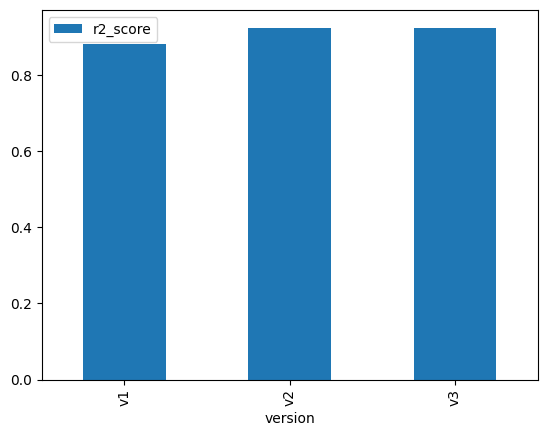

In [13]:
# plot model version performance comparison
comparison_df.plot(x='version', y='r2_score', kind='bar')
plt.show()